# 作业6

应用朴素贝叶斯算法对上周决策树分类所采用的数据集进行分类，并比较两种算法的分类准确率。

可采用e1071包中的naiveBayes函数或klaR包中的NavieBayes函数。

## 准备工作

### 加载包

In [1]:
library(MASS)
library(klaR)
library(rpart)
library(rpart.plot)
library(caret)

载入需要的程序包：ggplot2

载入需要的程序包：lattice



### 加载数据

In [2]:
weather <- read.csv("DTData.csv", sep=",")
# 将因变量设置为fact类型
weather$Play <- as.factor(weather$Play)
weather

Play,Outlook,Temperature,Humidity,Wind
<fct>,<chr>,<chr>,<chr>,<lgl>
yes,rainy,cool,normal,FALSE
no,rainy,cool,normal,TRUE
yes,overcast,hot,high,FALSE
no,sunny,mild,high,FALSE
yes,rainy,cool,normal,FALSE
yes,sunny,cool,normal,FALSE
yes,rainy,cool,normal,FALSE
yes,sunny,hot,normal,FALSE
yes,overcast,mild,high,TRUE


## 数据分析

### 构建模型

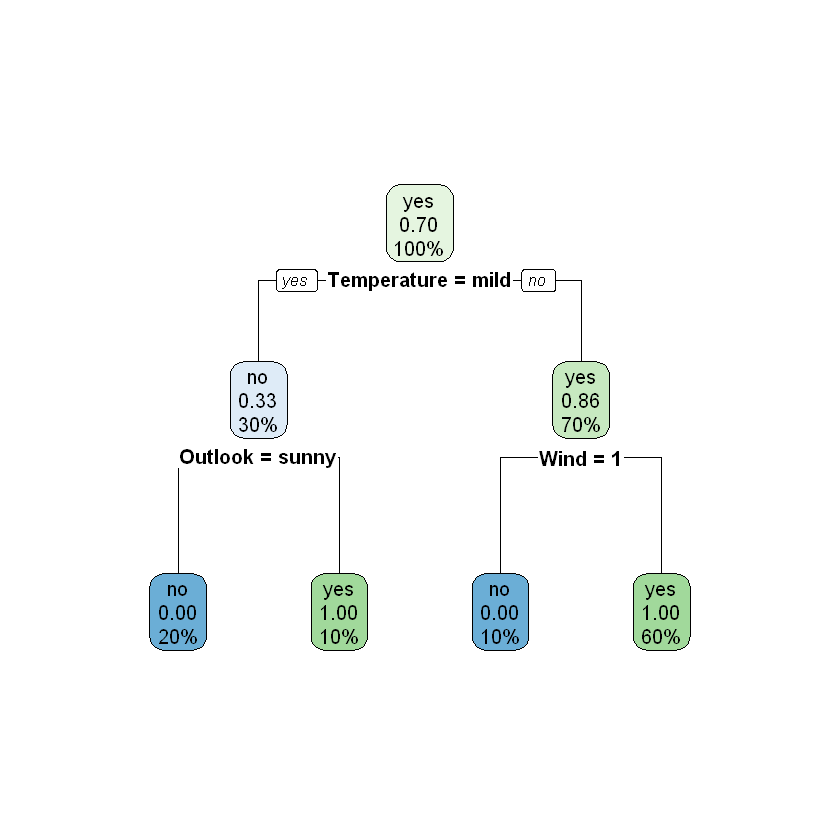

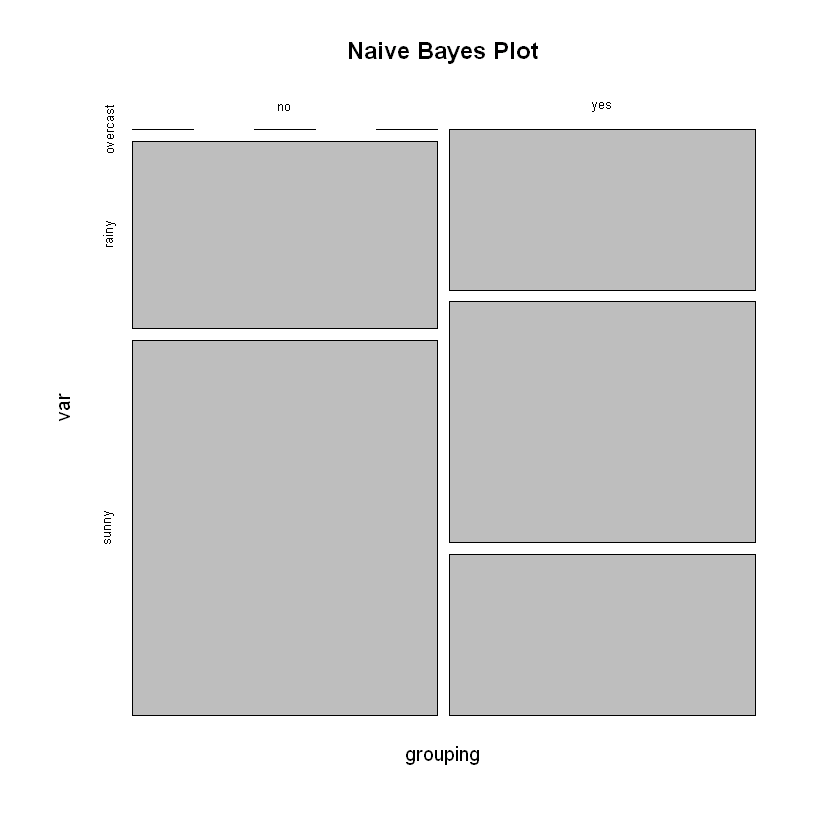

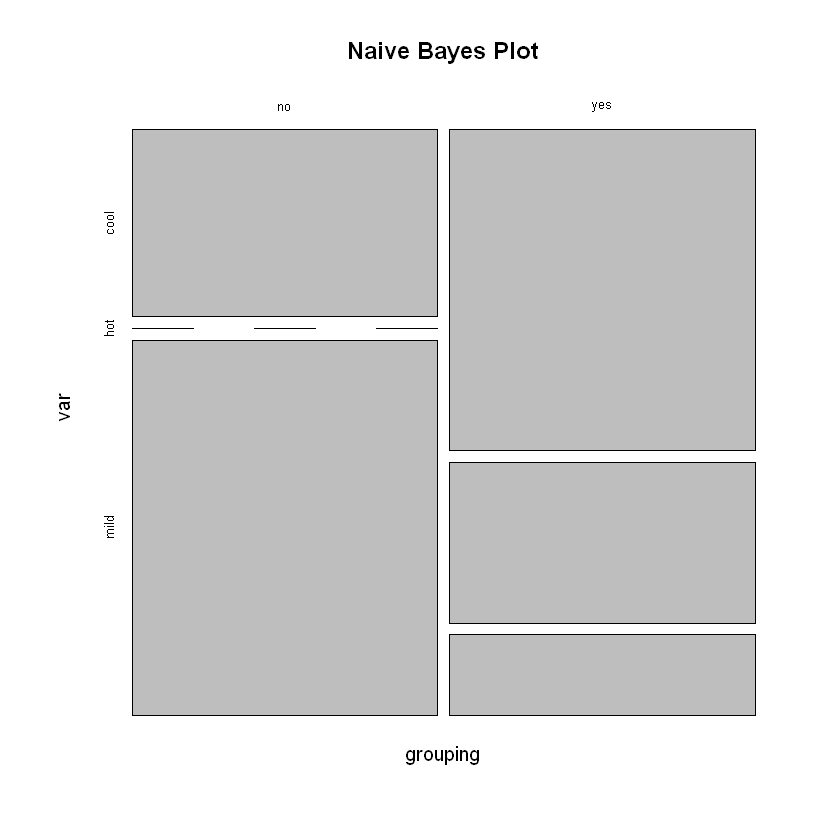

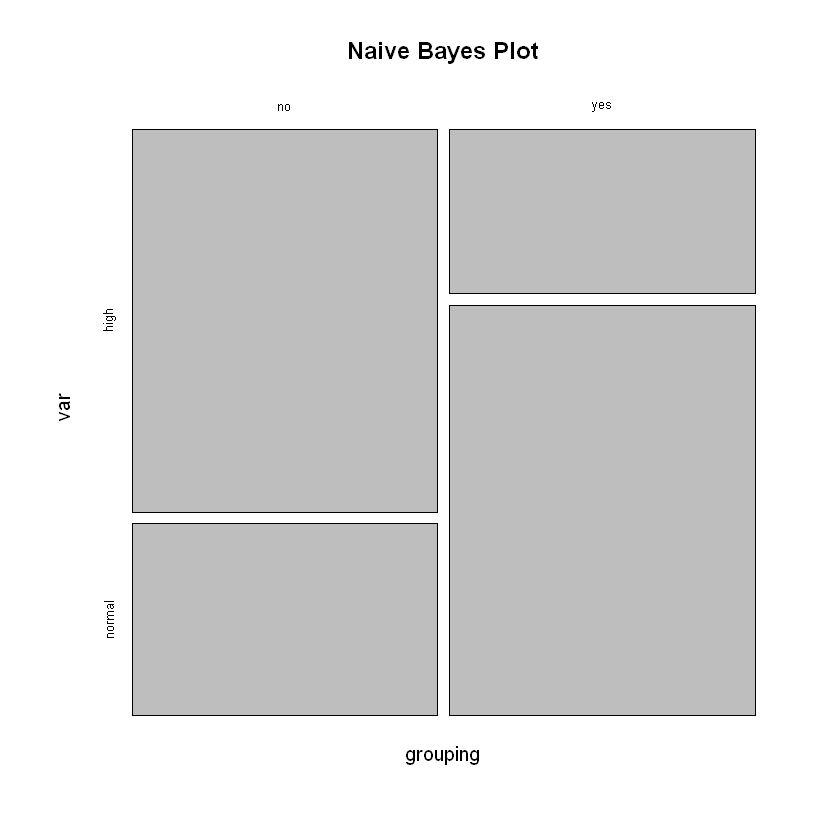

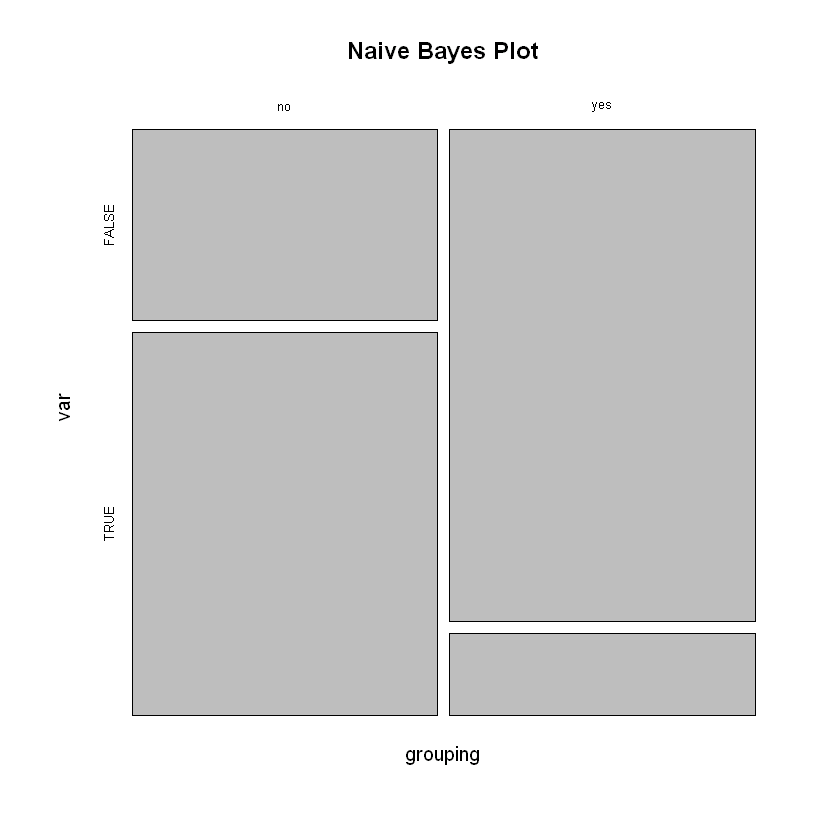

In [3]:
model_Dtree <- rpart(Play ~ Outlook + Temperature + Humidity + Wind, data = weather, method="class", control = rpart.control(minsplit = 1,minbucket = 1,cp = 0))
model_Bayes <- NaiveBayes(Play~Outlook+Temperature+Humidity+Wind,data = weather)
rpart.plot(model_Dtree)
plot(model_Bayes)

### 贝叶斯模型预测

In [4]:
Bayes_Result <- predict(model_Bayes,weather,type="class")
Bayes_Result

no,yes
3.408526e-02,0.9659147
2.974848e-01,0.7025152
4.763866e-06,0.9999952
8.089623e-01,0.1910377
3.408526e-02,0.9659147
9.572984e-02,0.9042702
3.408526e-02,0.9659147
6.347820e-04,0.9993652
7.082387e-02,0.9291761
9.807005e-01,0.0192995


In [5]:
Bayes_Matrix <- confusionMatrix(Bayes_Result$class,weather$Play)
Bayes_Matrix

Confusion Matrix and Statistics

          Reference
Prediction no yes
       no   2   0
       yes  1   7
                                         
               Accuracy : 0.9            
                 95% CI : (0.555, 0.9975)
    No Information Rate : 0.7            
    P-Value [Acc > NIR] : 0.1493         
                                         
                  Kappa : 0.7368         
                                         
 Mcnemar's Test P-Value : 1.0000         
                                         
            Sensitivity : 0.6667         
            Specificity : 1.0000         
         Pos Pred Value : 1.0000         
         Neg Pred Value : 0.8750         
             Prevalence : 0.3000         
         Detection Rate : 0.2000         
   Detection Prevalence : 0.2000         
      Balanced Accuracy : 0.8333         
                                         
       'Positive' Class : no             
                                         

### 决策树模型预测

In [6]:
DTree_Result <- predict(model_Dtree,weather,type="class")
DTree_Result

1   2   3   4   5   6   7   8   9  10 
yes  no yes  no yes yes yes yes yes  no 
Levels: no yes

In [7]:
DTree_Matrix <- confusionMatrix(DTree_Result,weather$Play)
DTree_Matrix

Confusion Matrix and Statistics

          Reference
Prediction no yes
       no   3   0
       yes  0   7
                                     
               Accuracy : 1          
                 95% CI : (0.6915, 1)
    No Information Rate : 0.7        
    P-Value [Acc > NIR] : 0.02825    
                                     
                  Kappa : 1          
                                     
 Mcnemar's Test P-Value : NA         
                                     
            Sensitivity : 1.0        
            Specificity : 1.0        
         Pos Pred Value : 1.0        
         Neg Pred Value : 1.0        
             Prevalence : 0.3        
         Detection Rate : 0.3        
   Detection Prevalence : 0.3        
      Balanced Accuracy : 1.0        
                                     
       'Positive' Class : no         
                                     

## 总结

从输出矩阵的Accuracy行中可以看到，决策树预测的准确率高于朴素贝叶斯算法。由于数据量较小，这里显示决策树的准确率为100%，贝叶斯的准确率为90%。不过随着数据量增多，贝叶斯算法的时间复杂度较小，其在速度上更有优势。